# **HMM GMM**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import scipy
from scipy.io import wavfile

In [2]:
# Append File path ke list
fpaths = []
labels = []
spoken = []

PATH = "./Audio"
print(os.listdir(PATH))

['apple', 'banana', 'book', 'cat', 'dog', 'eye', 'fast', 'god', 'human', 'kiwi', 'lime', 'orange', 'peach', 'pineapple']


In [3]:
for c in os.listdir(PATH):
    for f in os.listdir(PATH + "/" + c):
        fpaths.append(PATH + "/" + c + "/" + f)
        labels.append(c)
        if c not in spoken:
            spoken.append(c)

In [4]:
len(fpaths), len(labels), len(spoken)

(225, 225, 14)

In [15]:
# Cari Max Sample
data = np.zeros((len(fpaths), 32000))
max_sample = -1

for i, f in enumerate(fpaths):                            # looping sebanyak fpaths (225x)
    sample_rate, audio = wavfile.read(f)                  # baca file audio
    data[i, :audio.shape[0]] = audio                      # jika panjang audio lebih besar dari max_sample
    
    if audio.shape[0] > max_sample:                       # maka max_sample diupdate
        max_sample = audio.shape[0]

data = data[:, :max_sample]

# labelin 
all_labels = np.zeros(data.shape[0])

for n, l in enumerate(set(labels)):
    all_labels[np.array([i for i, label in enumerate(labels) if label == l])] = n
    print(n, l)

0 human
1 kiwi
2 peach
3 dog
4 fast
5 lime
6 book
7 orange
8 god
9 apple
10 cat
11 pineapple
12 eye
13 banana


(0.0, 3000.0)

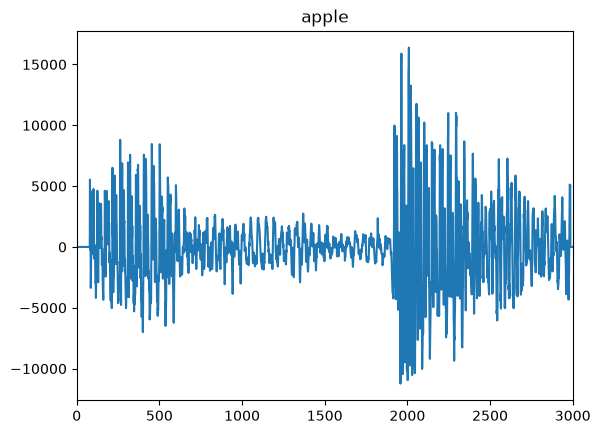

In [12]:
plt.plot(data[0, :]) # di lab 0 itu apple
plt.title(labels[0])
plt.xlim(0, 3000)

In [ ]:
# stft <- fft
# short time fourier transform
# fft -> frequency domain
# stft -> time frequency domain (mengambil FD dalam interval waktu kecil)
# hasil dari stft adalah spectrogram

def stft(x, fftsize=64, overlap_pct=0.5):
    hop = int(fftsize * (1 - overlap_pct))
    w = np.hanning(fftsize + 1)[:-1]
    raw = np.array([
        (np.fft.rfft(w * x[i:i + fftsize])) for i in range(0, len(x) - fftsize, hop)
    ])

    return raw[:, :(fftsize // 2)]  # downsample FFT

In [21]:
from numpy.lib.stride_tricks import as_strided

In [25]:
# spectral peak (Observed)
from numpy.lib.stride_tricks import as_strided

# [0, 1, 2, 3, 4]
'''
[0, 1, 2]
[1, 2, 3]
[., ., .]
........
'''
def find_peak(x, n_peaks, l_size=3, c_size=3, r_size=3, f = np.mean):
    win_size = l_size + c_size + r_size
    shape = x.shape[:-1] + (x.shape[-1] - win_size, win_size)
    strides = x.strides + (x.strides[-1], )
    xs = as_strided(x, shape=shape, strides=strides)            # xs = x as strided
    def is_peak(x):
        centered = np.argmax(x) == l_size + int(c_size / 2)     # cek apakah dia centered atau tidak nilainya 0 atau 1
        l = x[:l_size]
        c = x[l_size:l_size + c_size]
        r = x[-r_size:]
        passed = np.max(c) > np.max([f(l), f(r)])   # cek apakah nilai tengah lebih besar dari nilai kiri dan kanan
        if centered and passed:                     # validasi apakah dia udh centered
            return np.max(c)
        else:
            return -1

    r = np.apply_along_axis(is_peak, 1, xs)
    top = np.argsort(r, None)[::-1]
    heights = r[top][:n_peaks]                                    # ambil n_peaks terbesar
    top[top > -1] = top[top > -1] + l_size + int(c_size // 2.)    # top yang valid dikurangi dengan l_size + c_size/2

    return heights, top[:n_peaks]

In [26]:
all_obs = []
for i in range(data.shape[0]):
    d = np.abs(stft(data[i, :]))
    n_dim = 6
    obs = np.zeros((n_dim, data.shape[0]))

    for r in range(d.shape[0]):
        heights, top = find_peak(d[r, :], n_peaks=n_dim)
        obs[:, r] = top.copy()                              # copy untuk menghindari perubahan pada top asli
    
    if i % 10 == 0:
        print(f"Processed Obs: {i}")
    all_obs.append(obs)

all_obs = np.atleast_3d(all_obs)

Processed Obs: 0
Processed Obs: 10
Processed Obs: 20
Processed Obs: 30
Processed Obs: 40
Processed Obs: 50
Processed Obs: 60
Processed Obs: 70
Processed Obs: 80
Processed Obs: 90
Processed Obs: 100
Processed Obs: 110
Processed Obs: 120
Processed Obs: 130
Processed Obs: 140
Processed Obs: 150
Processed Obs: 160
Processed Obs: 170
Processed Obs: 180
Processed Obs: 190
Processed Obs: 200
Processed Obs: 210
Processed Obs: 220


In [27]:
all_obs

array([[[26.,  6.,  6., ...,  0.,  0.,  0.],
        [25., 18., 15., ...,  0.,  0.,  0.],
        [24., 26., 21., ...,  0.,  0.,  0.],
        [23., 23., 24., ...,  0.,  0.,  0.],
        [22., 22., 23., ...,  0.,  0.,  0.],
        [21., 25., 25., ...,  0.,  0.,  0.]],

       [[25.,  5.,  7., ...,  0.,  0.,  0.],
        [13., 22., 13., ...,  0.,  0.,  0.],
        [26., 12., 26., ...,  0.,  0.,  0.],
        [23., 24., 23., ...,  0.,  0.,  0.],
        [22., 23., 22., ...,  0.,  0.,  0.],
        [21., 25., 25., ...,  0.,  0.,  0.]],

       [[ 7., 25.,  4., ...,  0.,  0.,  0.],
        [25., 19., 13., ...,  0.,  0.,  0.],
        [17., 26., 25., ...,  0.,  0.,  0.],
        [23., 23., 23., ...,  0.,  0.,  0.],
        [22., 22., 22., ...,  0.,  0.,  0.],
        [26., 21., 26., ...,  0.,  0.,  0.]],

       ...,

       [[21., 16., 11., ...,  0.,  0.,  0.],
        [25., 25., 22., ...,  0.,  0.,  0.],
        [26., 26., 25., ...,  0.,  0.,  0.],
        [24., 23., 24., ...,  0.,  0